In [31]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, adjusted_rand_score, silhouette_score)
from IPython.display import display
SEEDS=[42,52,62]
OUT=Path('figures'); OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
DATASET='breast_cancer'
bundle=load_breast_cancer() if DATASET=='breast_cancer' else load_wine()
X=pd.DataFrame(bundle.data,columns=bundle.feature_names)
y=pd.Series(bundle.target,index=X.index,name='target')
CLASS_IDS=np.array(sorted(y.unique()))
CLASS_NAMES=list(bundle.target_names)
LABEL_MAP=dict(zip(CLASS_IDS,CLASS_NAMES))
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT/f'{DATASET}_{name}.png',dpi=160,bbox_inches='tight'); plt.show(); plt.close()
def interpret(message): print('Interpretation:',message)


def show_table(frame, title, decimals=4):
    """Display a real, live pandas table (rendered HTML), computed from the DataFrame."""
    styler=(frame.round(decimals).style
            .format(precision=decimals)
            .set_caption(f"{title} — {len(frame)} rows × {len(frame.columns)} columns")
            .set_table_styles([
                {'selector':'caption','props':'caption-side:top;text-align:left;font-weight:bold;font-size:1.05em;padding:6px 0;'},
                {'selector':'th','props':'text-align:center;white-space:nowrap;'},
                {'selector':'td','props':'text-align:right;white-space:nowrap;'}]))
    display(styler)


In [32]:

print('Dataset:',DATASET,'X shape:',X.shape,'y shape:',y.shape)
show_table(X.head(), 'First five feature rows')
print('Feature names:',list(X.columns))
print('Target labels:',CLASS_IDS.tolist())
print('Target names:',CLASS_NAMES)
print('Label mapping:',LABEL_MAP)
print('Samples per class:'); show_table(y.value_counts().sort_index().rename(index=LABEL_MAP).to_frame('count'), 'Class counts')
assert 'target' not in X.columns and X.index.equals(y.index)



Dataset: breast_cancer X shape: (569, 30) y shape: (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target labels: [0, 1]
Target names: [np.str_('malignant'), np.str_('benign')]
Label mapping: {np.int64(0): np.str_('malignant'), np.int64(1): np.str_('benign')}
Samples per class:


,count
target,
malignant,212
benign,357


In [33]:

missing=X.isna().sum().to_frame('missing_count'); show_table(missing, 'Missing values per feature')
duplicates=int(X.duplicated().sum()); print('Duplicate feature rows:',duplicates)
print('Missing values:', 'none present' if missing.sum().iloc[0]==0 else 'present; no rows imputed before splitting')
print('Duplicate rows:', 'none present' if duplicates==0 else f'{duplicates} present; retained')
interpret('No artificial missing values were created. Any missingness is reported without preprocessing the complete dataset.')


,missing_count
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Duplicate feature rows: 0
Missing values: none present
Duplicate rows: none present
Interpretation: No artificial missing values were created. Any missingness is reported without preprocessing the complete dataset.


In [34]:

q1=X.quantile(.25); q3=X.quantile(.75); iqr=q3-q1
outlier_flags=(X.lt(q1-1.5*iqr)|X.gt(q3+1.5*iqr))
outlier_counts=outlier_flags.sum().sort_values(ascending=False).to_frame('IQR_flagged_count')
show_table(outlier_counts, 'Potential IQR outliers')
print('Top flagged features:',outlier_counts.head(3).index.tolist())
interpret('IQR flags indicate potential extremes, not errors. Large/small observations can dominate Euclidean KNN/K-Means distances, influence tree thresholds, and alter GaussianNB estimated means/variances. No observations are removed or clipped.')


,IQR_flagged_count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


Top flagged features: ['area error', 'radius error', 'perimeter error']
Interpretation: IQR flags indicate potential extremes, not errors. Large/small observations can dominate Euclidean KNN/K-Means distances, influence tree thresholds, and alter GaussianNB estimated means/variances. No observations are removed or clipped.


In [35]:

stats=pd.DataFrame({'mean':X.mean(),'median':X.median(),'min':X.min(),'max':X.max(),
                    'std':X.std(),'Q1':X.quantile(.25),'Q3':X.quantile(.75)})
show_table(stats, 'Descriptive statistics for all features')
stats.to_csv(f'{DATASET}_descriptive_statistics.csv')



,mean,median,min,max,std,Q1,Q3
mean radius,14.1273,13.3700,6.9810,28.1100,3.5240,11.7000,15.7800
mean texture,19.2896,18.8400,9.7100,39.2800,4.3010,16.1700,21.8000
mean perimeter,91.9690,86.2400,43.7900,188.5000,24.2990,75.1700,104.1000
mean area,654.8891,551.1000,143.5000,2501.0000,351.9141,420.3000,782.7000
mean smoothness,0.0964,0.0959,0.0526,0.1634,0.0141,0.0864,0.1053
mean compactness,0.1043,0.0926,0.0194,0.3454,0.0528,0.0649,0.1304
mean concavity,0.0888,0.0615,0.0000,0.4268,0.0797,0.0296,0.1307
mean concave points,0.0489,0.0335,0.0000,0.2012,0.0388,0.0203,0.0740
mean symmetry,0.1812,0.1792,0.1060,0.3040,0.0274,0.1619,0.1957
mean fractal dimension,0.0628,0.0615,0.0500,0.0974,0.0071,0.0577,0.0661


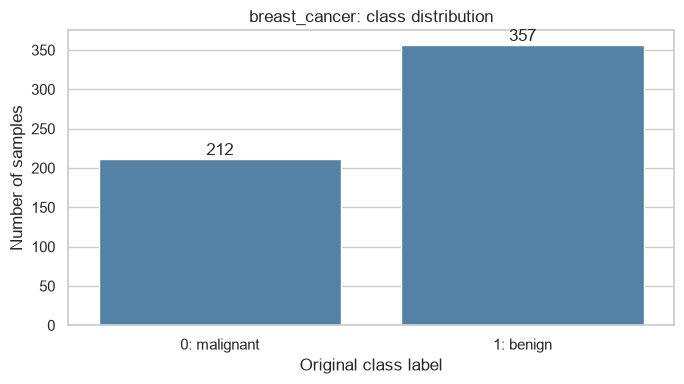

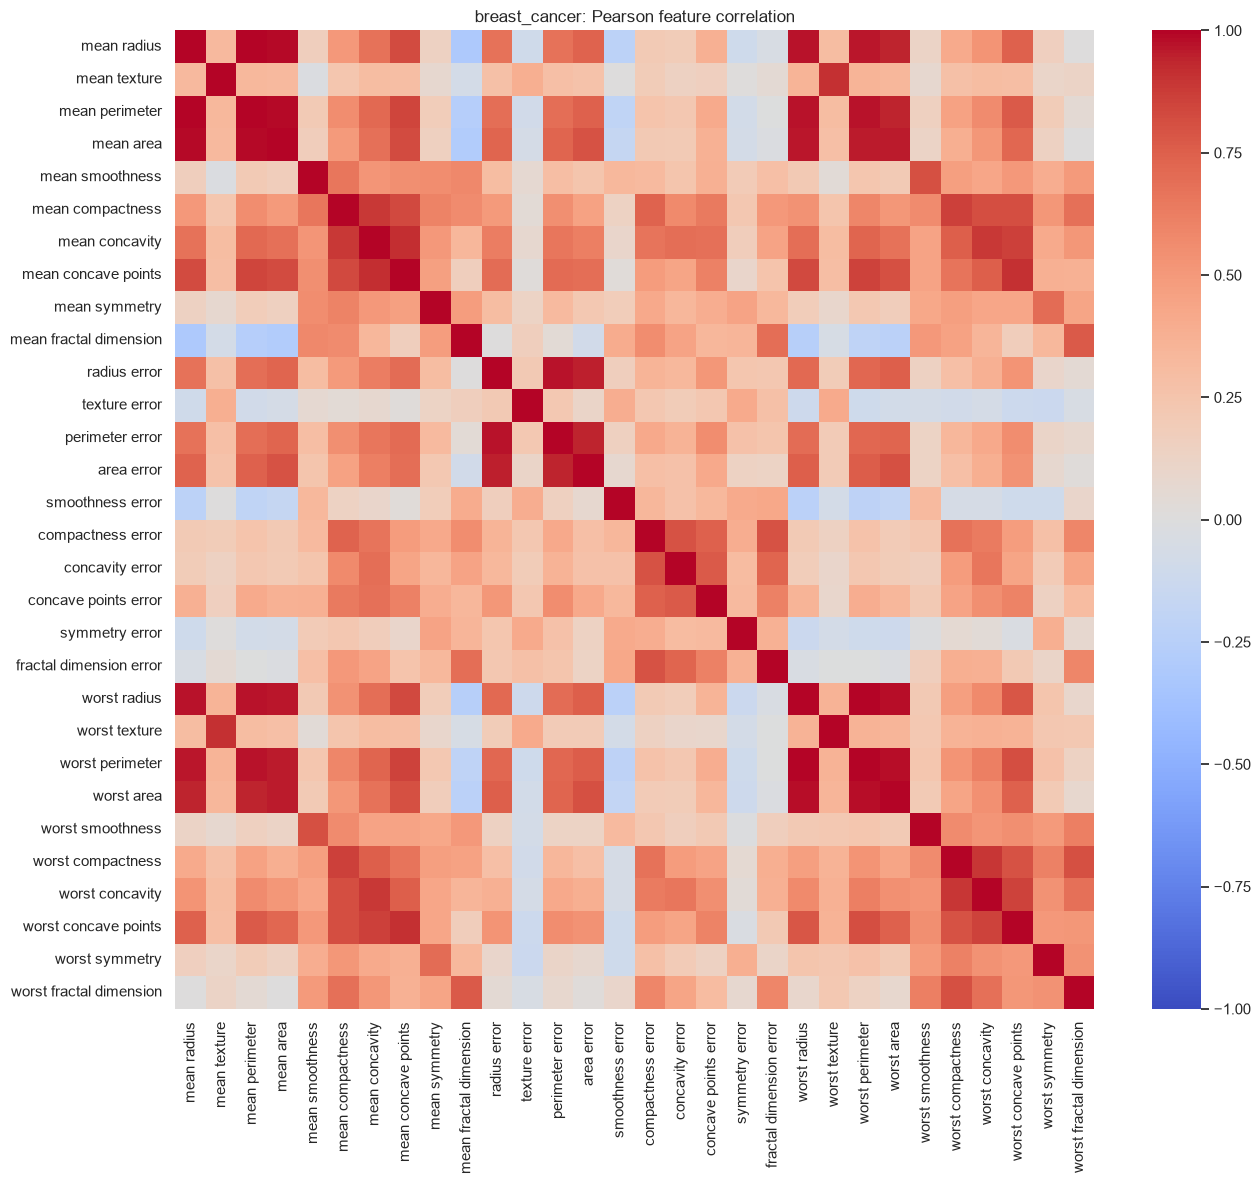

Three strongest UNIQUE feature pairs (no diagonal/mirrors):
  mean radius / mean perimeter: r=0.9979
  worst radius / worst perimeter: r=0.9937
  mean radius / mean area: r=0.9874


In [36]:

fig,ax=plt.subplots(figsize=(7,4)); counts=y.value_counts().sort_index()
sns.barplot(x=[f'{i}: {LABEL_MAP[i]}' for i in counts.index],y=counts.values,ax=ax,color='steelblue')
ax.set(xlabel='Original class label',ylabel='Number of samples',title=f'{DATASET}: class distribution')
for i,v in enumerate(counts.values): ax.text(i,v,str(v),ha='center',va='bottom')
savefig('class_distribution')
corr=X.corr(method='pearson')
fig,ax=plt.subplots(figsize=(max(10,len(X.columns)*.45),max(8,len(X.columns)*.40)))
sns.heatmap(corr,cmap='coolwarm',center=0,vmin=-1,vmax=1,ax=ax)
ax.set_title(f'{DATASET}: Pearson feature correlation'); savefig('correlation_heatmap')
pairs=[]
for i in range(len(corr.columns)):
    for j in range(i+1,len(corr.columns)):
        pairs.append((corr.columns[i],corr.columns[j],corr.iloc[i,j]))
strongest=sorted(pairs,key=lambda p:abs(p[2]),reverse=True)[:3]
print('Three strongest UNIQUE feature pairs (no diagonal/mirrors):')
for a,b,r in strongest: print(f'  {a} / {b}: r={r:.4f}')



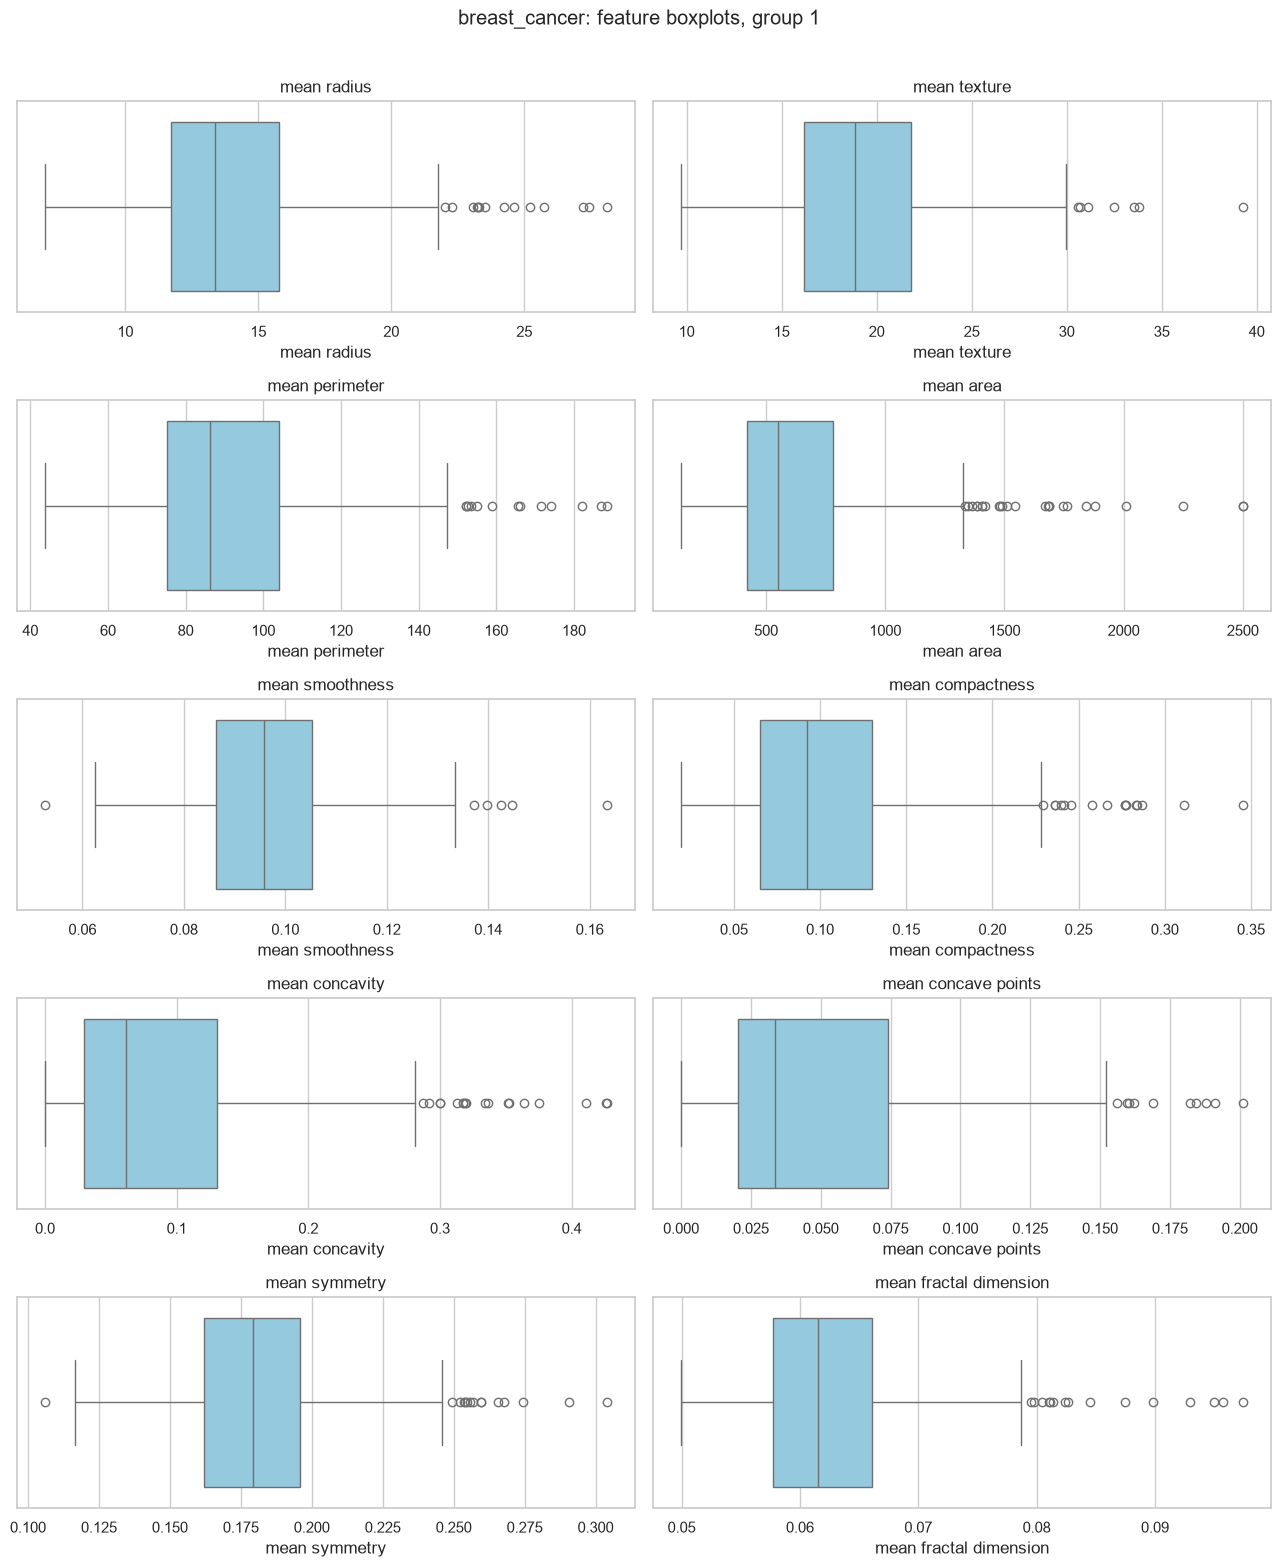

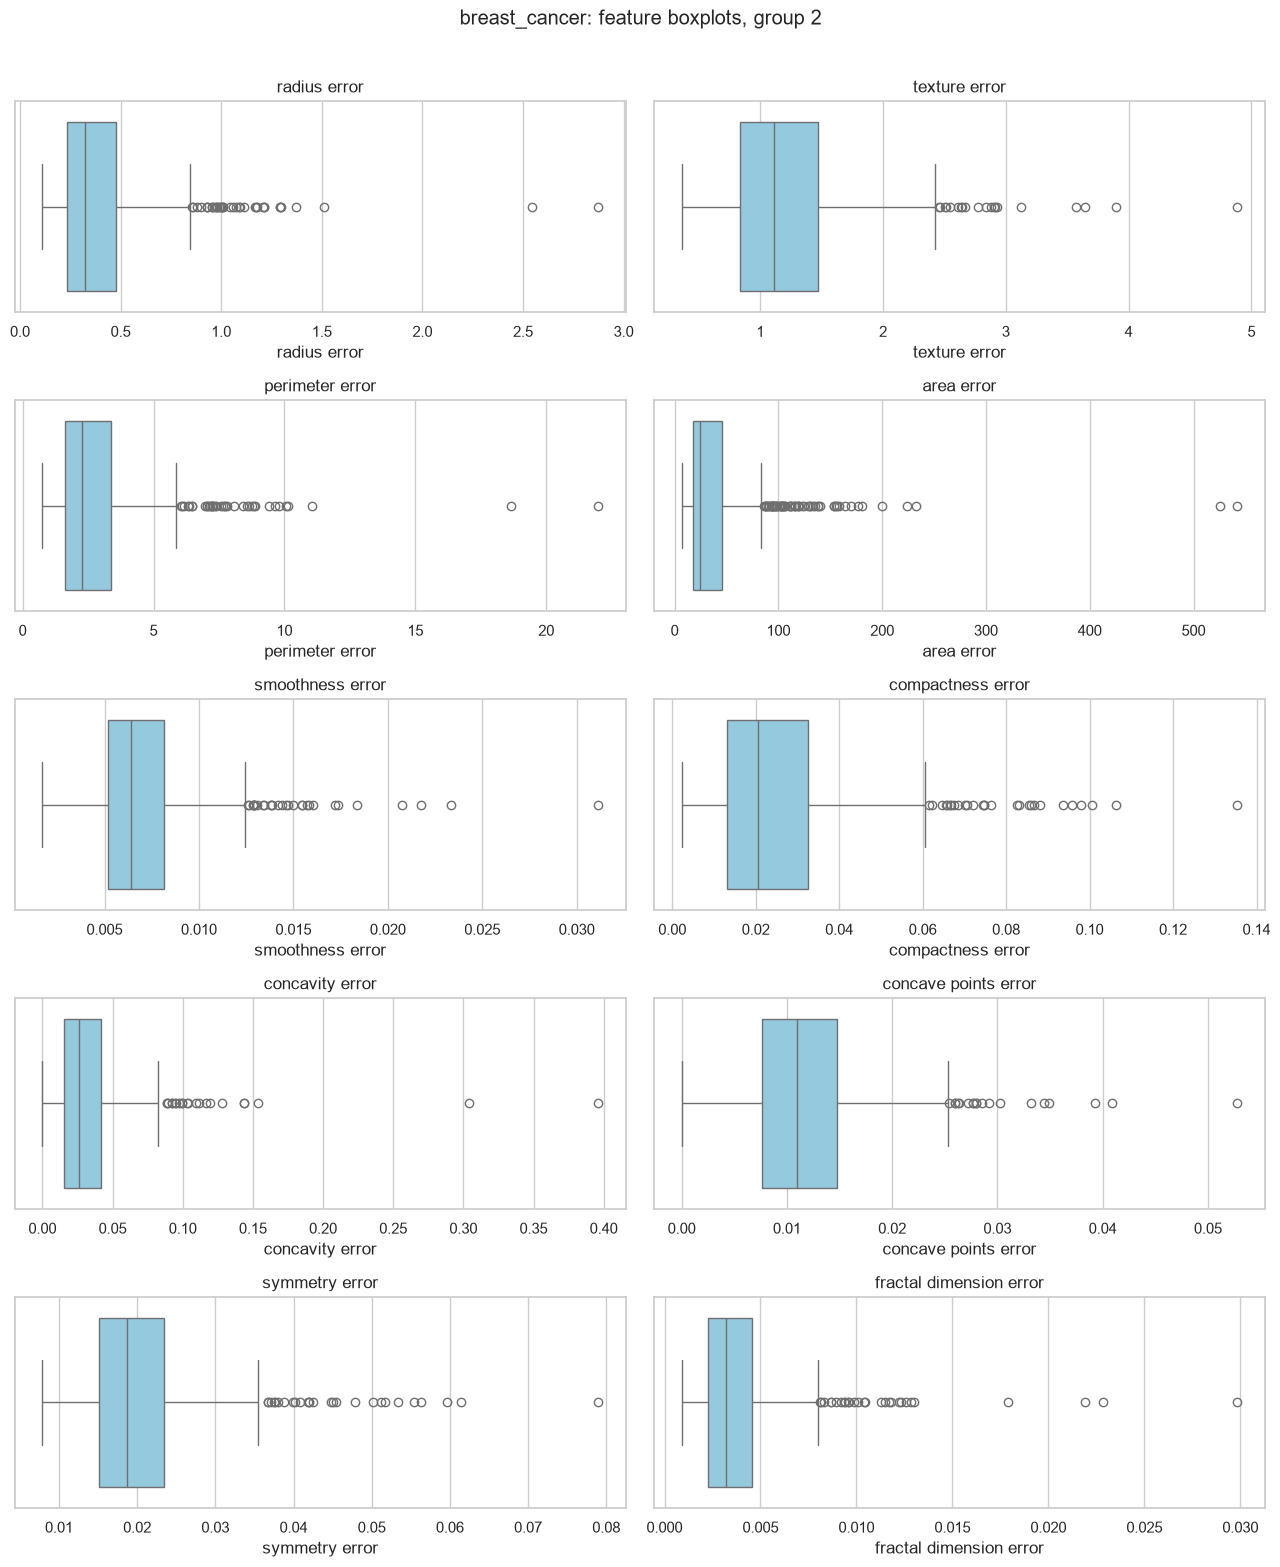

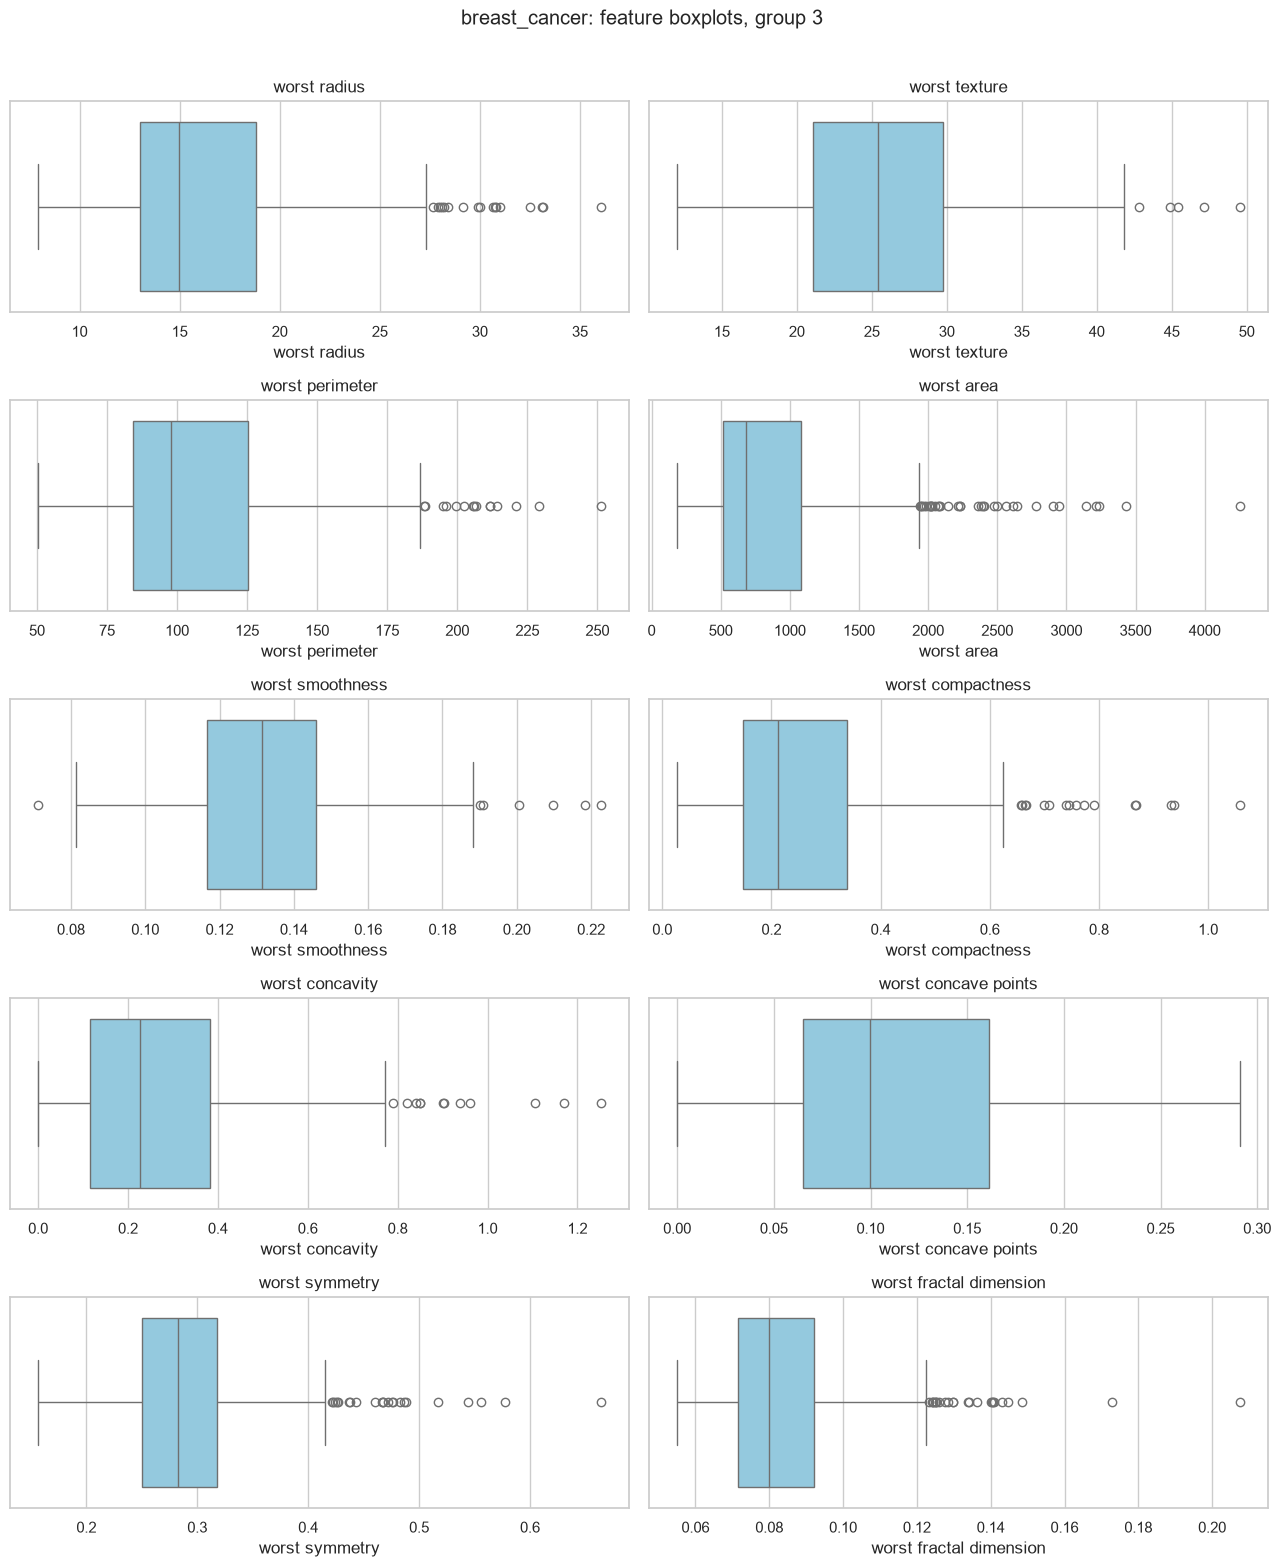

Observation 1: Widest raw ranges: {'worst area': 4068.8, 'mean area': 2357.5, 'area error': 535.398}
Observation 2: Most IQR-flagged features: {'area error': {'IQR_flagged_count': 65}, 'radius error': {'IQR_flagged_count': 38}, 'perimeter error': {'IQR_flagged_count': 38}}


In [37]:

for group_no, start in enumerate(range(0,X.shape[1],10),start=1):
    cols=list(X.columns[start:start+10]); n=len(cols)
    fig,axes=plt.subplots((n+1)//2,2,figsize=(13,3.1*((n+1)//2)))
    axes=np.array(axes).reshape(-1)
    for ax,col in zip(axes,cols): sns.boxplot(x=X[col],ax=ax,color='skyblue'); ax.set_title(col)
    for ax in axes[n:]: ax.axis('off')
    fig.suptitle(f'{DATASET}: feature boxplots, group {group_no}',y=1.01)
    savefig(f'boxplots_{group_no}')
print('Observation 1: Widest raw ranges:',(X.max()-X.min()).sort_values(ascending=False).head(3).to_dict())
print('Observation 2: Most IQR-flagged features:',outlier_counts.head(3).T.to_dict())



In [38]:

X_rem,X_test,y_rem,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=42)
splits={}
for seed in SEEDS:
    X_train,X_val,y_train,y_val=train_test_split(X_rem,y_rem,test_size=.125,stratify=y_rem,random_state=seed)
    scaler=StandardScaler().fit(X_train)
    splits[seed]={'X_train':X_train,'X_val':X_val,'y_train':y_train,'y_val':y_val,
                  'raw_train':X_train,'raw_val':X_val,
                  'scaled_train':pd.DataFrame(scaler.transform(X_train),columns=X.columns,index=X_train.index),
                  'scaled_val':pd.DataFrame(scaler.transform(X_val),columns=X.columns,index=X_val.index),
                  'scaler':scaler}
    print(f'Seed {seed}: train={len(X_train)}, validation={len(X_val)}, fixed test={len(X_test)}; overlap=',len(set(X_train.index)&set(X_test.index)))
assert all(set(s['X_train'].index).isdisjoint(X_test.index) and set(s['X_val'].index).isdisjoint(X_test.index) for s in splits.values())
assert len(set(X_test.index))==len(X_test)


Seed 42: train=398, validation=57, fixed test=114; overlap= 0
Seed 52: train=398, validation=57, fixed test=114; overlap= 0
Seed 62: train=398, validation=57, fixed test=114; overlap= 0


In [39]:

def make_classifier(family,param,seed):
    if family=='Decision Tree': return DecisionTreeClassifier(max_depth=param,random_state=seed)
    if family=='KNN': return KNeighborsClassifier(n_neighbors=param,weights='uniform',metric='euclidean')
    return GaussianNB()
def undefined_classes(y_true,y_pred,labels):
    # Undefined precision when no predicted instances; undefined recall when no actual instances.
    return {'precision':[int(c) for c in labels if np.sum(y_pred==c)==0],
            'recall':[int(c) for c in labels if np.sum(y_true==c)==0]}
def evaluate(model,features,labels):
    pred=model.predict(features)
    proba=model.predict_proba(features)
    assert np.array_equal(model.classes_,CLASS_IDS), 'Probability columns do not match original class IDs'
    if DATASET=='breast_cancer':
        binary=(np.asarray(labels)==0).astype(int)
        auc=roc_auc_score(binary,proba[:,list(model.classes_).index(0)])
    else:
        auc=roc_auc_score(labels,proba,multi_class='ovr',average='macro',labels=model.classes_)
    return {'accuracy':accuracy_score(labels,pred),
            'macro_precision':precision_score(labels,pred,average='macro',zero_division=0),
            'macro_recall':recall_score(labels,pred,average='macro',zero_division=0),
            'macro_f1':f1_score(labels,pred,average='macro',zero_division=0),
            'roc_auc':auc,'undefined':undefined_classes(np.asarray(labels),pred,CLASS_IDS)}
records=[]
for seed in SEEDS:
    s=splits[seed]
    for representation in ['raw','scaled']:
        tr=s[f'{representation}_train']; va=s[f'{representation}_val']
        for family,parameters in [('Decision Tree',[2,3,5,10,None]),('KNN',[1,3,5,7,11]),('GaussianNB',['default'])]:
            for param in parameters:
                model=make_classifier(family,param,seed)
                model.fit(tr,s['y_train'])
                train_f1=f1_score(s['y_train'],model.predict(tr),average='macro',zero_division=0)
                metrics=evaluate(model,va,s['y_val'])
                records.append({'seed':seed,'representation':representation,'model':family,'parameter':str(param),
                                'train_macro_f1':train_f1,**metrics})
runs=pd.DataFrame(records)
assert len(runs)==66
runs['undefined_precision_classes']=runs['undefined'].map(lambda d:str(d['precision']))
runs['undefined_recall_classes']=runs['undefined'].map(lambda d:str(d['recall']))
runs=runs.drop(columns=['undefined'])
show_table(runs, 'All 66 classification runs')
runs.to_csv(f'{DATASET}_classification_66_runs.csv',index=False)
for col,label in [('undefined_precision_classes','Undefined precision instances'),('undefined_recall_classes','Undefined recall instances')]:
    bad=runs[runs[col]!='[]'][['seed','model','parameter',col]]
    if bad.empty: print(label+': none')
    else: show_table(bad,label)


,seed,representation,model,parameter,train_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,roc_auc,undefined_precision_classes,undefined_recall_classes
0,42,raw,Decision Tree,2,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757,[],[]
1,42,raw,Decision Tree,3,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193,[],[]
2,42,raw,Decision Tree,5,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213,[],[]
3,42,raw,Decision Tree,10,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246,[],[]
4,42,raw,Decision Tree,None,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246,[],[]
5,42,raw,KNN,1,1.0000,0.8596,0.8553,0.8393,0.8459,0.8393,[],[]
6,42,raw,KNN,3,0.9567,0.8772,0.8803,0.8532,0.8636,0.9160,[],[]
7,42,raw,KNN,5,0.9487,0.8947,0.8947,0.8770,0.8845,0.9299,[],[]
8,42,raw,KNN,7,0.9459,0.9123,0.9095,0.9008,0.9048,0.9511,[],[]
9,42,raw,KNN,11,0.9431,0.9298,0.9342,0.9147,0.9230,0.9550,[],[]


Undefined precision instances: none
Undefined recall instances: none


In [40]:

metric_cols=['accuracy','macro_precision','macro_recall','macro_f1','roc_auc','train_macro_f1']
summary=runs.groupby(['representation','model','parameter'],sort=False)[metric_cols].agg(['mean','std'])
summary.columns=[f'{metric}_{stat}' for metric,stat in summary.columns]
summary=summary.reset_index()
assert len(summary)==22
show_table(summary, '22 configurations: mean and standard deviation')
summary.to_csv(f'{DATASET}_classification_22_summary.csv',index=False)

selected=summary.sort_values(['macro_f1_mean','roc_auc_mean'],ascending=[False,False],kind='stable').iloc[0]
print('SELECTED:',selected[['model','parameter','representation','macro_f1_mean','macro_f1_std','roc_auc_mean']].to_dict())



,representation,model,parameter,accuracy_mean,accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,roc_auc_mean,roc_auc_std,train_macro_f1_mean,train_macro_f1_std
0,raw,Decision Tree,2,0.9181,0.0203,0.9131,0.0161,0.9120,0.0308,0.9117,0.0236,0.9220,0.0404,0.9527,0.0041
1,raw,Decision Tree,3,0.9240,0.0268,0.9199,0.0231,0.9167,0.0364,0.9177,0.0304,0.9414,0.0209,0.9739,0.0042
2,raw,Decision Tree,5,0.9240,0.0203,0.9167,0.0182,0.9233,0.0308,0.9188,0.0227,0.9301,0.0250,0.9946,0.0047
3,raw,Decision Tree,10,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,1.0000,0.0000
4,raw,Decision Tree,None,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,1.0000,0.0000
5,raw,KNN,1,0.8889,0.0506,0.8836,0.0491,0.8757,0.0630,0.8786,0.0566,0.8757,0.0630,1.0000,0.0000
6,raw,KNN,3,0.9006,0.0405,0.8998,0.0420,0.8849,0.0467,0.8910,0.0449,0.9299,0.0235,0.9558,0.0042
7,raw,KNN,5,0.9181,0.0268,0.9174,0.0275,0.9054,0.0310,0.9107,0.0297,0.9480,0.0348,0.9469,0.0032
8,raw,KNN,7,0.9123,0.0000,0.9133,0.0066,0.8975,0.0057,0.9040,0.0013,0.9581,0.0291,0.9442,0.0032
9,raw,KNN,11,0.9240,0.0101,0.9351,0.0145,0.9034,0.0120,0.9155,0.0113,0.9605,0.0311,0.9404,0.0028


SELECTED: {'model': 'KNN', 'parameter': '7', 'representation': 'scaled', 'macro_f1_mean': 0.9676749826749828, 'macro_f1_std': 0.029718024557980914, 'roc_auc_mean': 0.9781746031746031}


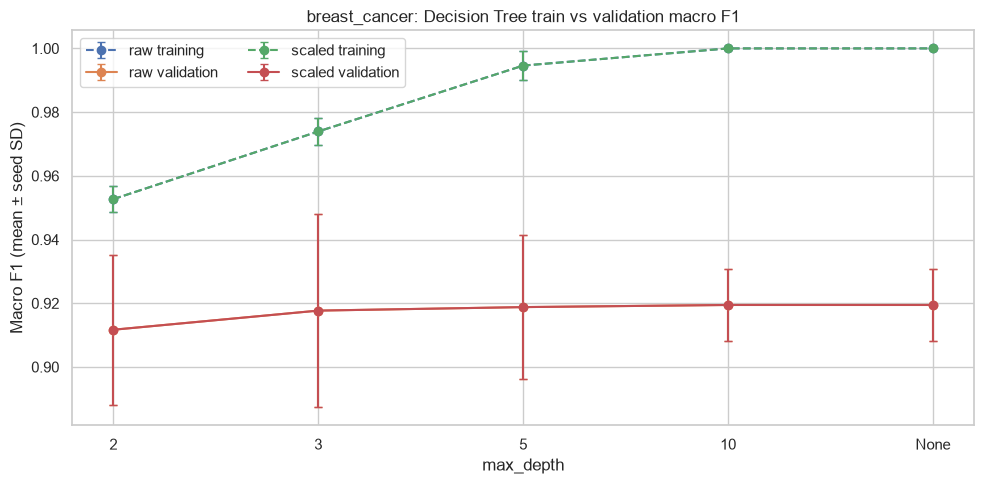

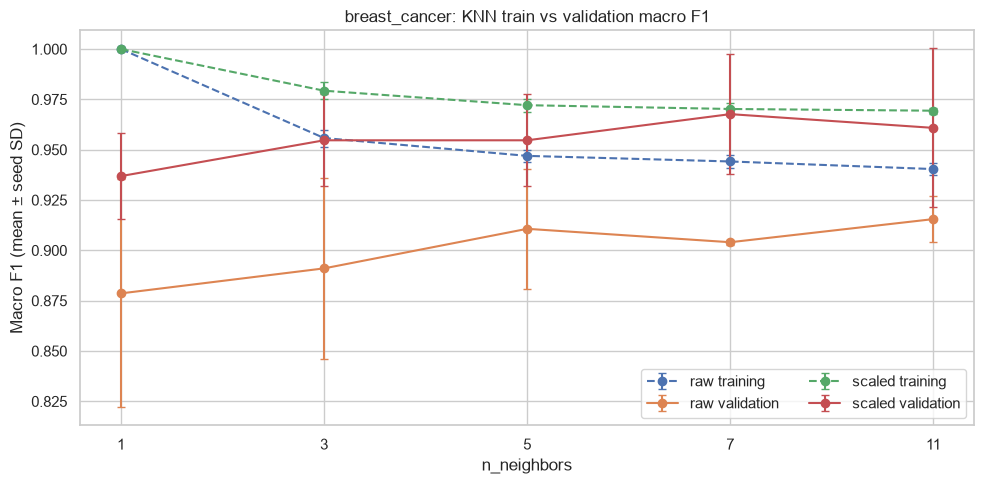

In [41]:

for family,parameters,filename,xlabel in [('Decision Tree',['2','3','5','10','None'],'tree_depth','max_depth'),
                                           ('KNN',['1','3','5','7','11'],'knn_neighbors','n_neighbors')]:
    fig,ax=plt.subplots(figsize=(10,5))
    for rep in ['raw','scaled']:
        sub=summary[(summary.model==family)&(summary.representation==rep)].set_index('parameter').loc[parameters]
        xx=np.arange(len(parameters))
        for metric,style in [('train_macro_f1','--'),('macro_f1','-')]:
            ax.errorbar(xx,sub[f'{metric}_mean'],yerr=sub[f'{metric}_std'].fillna(0),
                        marker='o',linestyle=style,capsize=3,label=f'{rep} {"training" if metric=="train_macro_f1" else "validation"}')
    ax.set_xticks(np.arange(len(parameters)),parameters)
    ax.set(xlabel=xlabel,ylabel='Macro F1 (mean ± seed SD)',title=f'{DATASET}: {family} train vs validation macro F1')
    ax.legend(ncol=2); savefig(filename)



FINAL TEST METRICS: {'accuracy': 0.9736842105263158, 'macro_precision': 0.98, 'macro_recall': 0.9642857142857143, 'macro_f1': 0.9712773998488284, 'roc_auc': 0.9884259259259259, 'undefined': {'precision': [], 'recall': []}}


,precision,recall,f1-score,support
malignant,1.0000,0.9286,0.9630,42.0000
benign,0.9600,1.0000,0.9796,72.0000
accuracy,0.9737,0.9737,0.9737,0.9737
macro avg,0.9800,0.9643,0.9713,114.0000
weighted avg,0.9747,0.9737,0.9735,114.0000


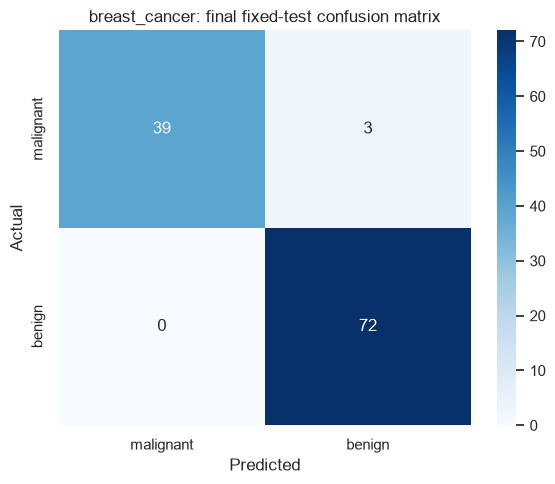

Malignant-positive counts: TP=39, FN=3, FP=0, TN=72
Manual one-vs-rest metrics for malignant : {'TP': np.int64(39), 'FP': np.int64(0), 'FN': np.int64(3), 'precision': np.float64(1.0), 'recall': np.float64(0.9285714285714286), 'f1': np.float64(0.9629629629629629)}
Classification report SAME CLASS: {'precision': 1.0, 'recall': 0.9285714285714286, 'f1-score': 0.9629629629629629}


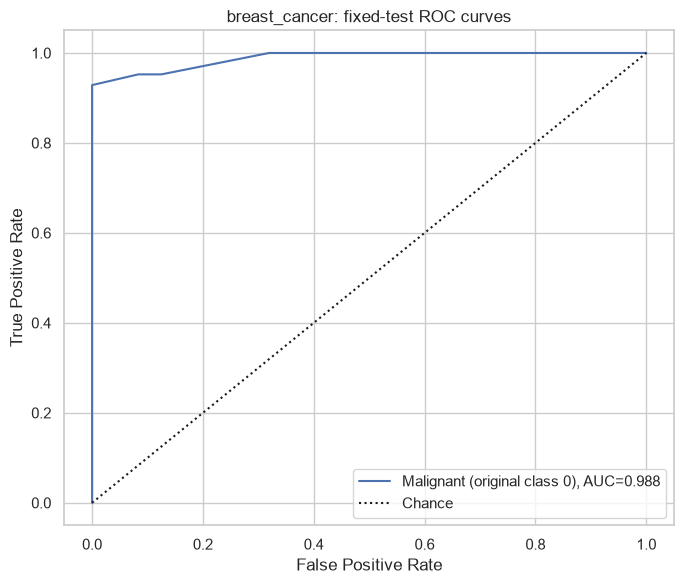

In [42]:

rep=selected['representation']; family=selected['model']; p=selected['parameter']
param=None if p=='None' else ('default' if p=='default' else int(p))
final_scaler=StandardScaler().fit(X_rem) if rep=='scaled' else None
final_train=pd.DataFrame(final_scaler.transform(X_rem),columns=X.columns,index=X_rem.index) if final_scaler else X_rem
final_test=pd.DataFrame(final_scaler.transform(X_test),columns=X.columns,index=X_test.index) if final_scaler else X_test
final_model=make_classifier(family,param,42).fit(final_train,y_rem)
test_pred=final_model.predict(final_test)
test_probs=final_model.predict_proba(final_test)
assert np.array_equal(final_model.classes_,CLASS_IDS)
print('FINAL TEST METRICS:',evaluate(final_model,final_test,y_test))
report=classification_report(y_test,test_pred,labels=CLASS_IDS,target_names=CLASS_NAMES,output_dict=True,zero_division=0)
show_table(pd.DataFrame(report).T, 'Final test classification report')
cm=confusion_matrix(y_test,test_pred,labels=CLASS_IDS)
fig,ax=plt.subplots(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax)
ax.set(xlabel='Predicted',ylabel='Actual',title=f'{DATASET}: final fixed-test confusion matrix')
savefig('final_confusion_matrix')
if DATASET=='breast_cancer':
    TP, FN, FP, TN=cm[0,0],cm[0,1],cm[1,0],cm[1,1]
    print(f'Malignant-positive counts: TP={TP}, FN={FN}, FP={FP}, TN={TN}')
    chosen_class=0
else:
    chosen_class=0
    offdiag=cm.copy(); np.fill_diagonal(offdiag,0)
    if offdiag.max()==0: print('Wine: no off-diagonal errors in the test confusion matrix.')
    else:
        i,j=np.unravel_index(np.argmax(offdiag),offdiag.shape)
        print(f'Largest wine confusion: actual class {CLASS_IDS[i]} ({CLASS_NAMES[i]}) predicted as {CLASS_IDS[j]} ({CLASS_NAMES[j]}): {offdiag[i,j]} samples.')
idx=list(CLASS_IDS).index(chosen_class)
tp=cm[idx,idx]; fp=cm[:,idx].sum()-tp; fn=cm[idx,:].sum()-tp
p_manual=tp/(tp+fp) if tp+fp else np.nan
r_manual=tp/(tp+fn) if tp+fn else np.nan
f_manual=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan
print('Manual one-vs-rest metrics for',CLASS_NAMES[idx],':',{'TP':tp,'FP':fp,'FN':fn,'precision':p_manual,'recall':r_manual,'f1':f_manual})
print('Classification report SAME CLASS:',{k:report[CLASS_NAMES[idx]][k] for k in ['precision','recall','f1-score']})
if np.isnan(p_manual) or np.isnan(r_manual) or np.isnan(f_manual): print('At least one manual metric is undefined due to a zero denominator; report substitutes zero.')
else:
    assert np.allclose([p_manual,r_manual,f_manual],[report[CLASS_NAMES[idx]][k] for k in ['precision','recall','f1-score']])
fig,ax=plt.subplots(figsize=(7,6))
if DATASET=='breast_cancer':
    yy=(y_test.to_numpy()==0).astype(int)
    scores=test_probs[:,list(final_model.classes_).index(0)]
    fpr,tpr,_=roc_curve(yy,scores)
    auc=roc_auc_score(yy,scores)
    ax.plot(fpr,tpr,label=f'Malignant (original class 0), AUC={auc:.3f}')
else:
    for i,c in enumerate(CLASS_IDS):
        yy=(y_test.to_numpy()==c).astype(int)
        fpr,tpr,_=roc_curve(yy,test_probs[:,i]); area=roc_auc_score(yy,test_probs[:,i])
        ax.plot(fpr,tpr,label=f'{CLASS_NAMES[i]} vs rest, AUC={area:.3f}')
    print('Wine macro OVR AUC:',roc_auc_score(y_test,test_probs,multi_class='ovr',average='macro',labels=CLASS_IDS))
ax.plot([0,1],[0,1],'k:',label='Chance')
ax.set(xlabel='False Positive Rate',ylabel='True Positive Rate',title=f'{DATASET}: fixed-test ROC curves')
ax.legend(); savefig('final_roc')



In [43]:

cluster_records=[]
for seed in SEEDS:
    s=splits[seed]
    for rep in ['raw','scaled']:
        tr=s[f'{rep}_train']; va=s[f'{rep}_val']
        km=KMeans(n_clusters=len(CLASS_IDS),random_state=seed,n_init=10)
        km.fit(tr) # no target labels passed
        clusters=km.predict(va)
        silhouette=silhouette_score(va,clusters) if 1<len(np.unique(clusters))<len(va) else np.nan
        cluster_records.append({'seed':seed,'representation':rep,'train_inertia':km.inertia_,
                                'validation_ARI':adjusted_rand_score(s['y_val'],clusters),
                                'validation_silhouette':silhouette,'validation_clusters':len(np.unique(clusters))})
cluster_runs=pd.DataFrame(cluster_records)
assert len(cluster_runs)==6
show_table(cluster_runs, 'Six K-Means runs')
cluster_runs.to_csv(f'{DATASET}_kmeans_6_runs.csv',index=False)
cluster_summary=cluster_runs.groupby('representation',sort=False)[['train_inertia','validation_ARI','validation_silhouette']].agg(['mean','std'])
cluster_summary.columns=[f'{m}_{stat}' for m,stat in cluster_summary.columns]
cluster_summary=cluster_summary.reset_index()
assert len(cluster_summary)==2
show_table(cluster_summary, 'K-Means mean and standard deviation')
cluster_summary.to_csv(f'{DATASET}_kmeans_2_summary.csv',index=False)


,seed,representation,train_inertia,validation_ARI,validation_silhouette,validation_clusters
0,42,raw,51565380.5448,0.3995,0.6387,2
1,42,scaled,7918.8101,0.4516,0.2854,2
2,52,raw,49190782.1788,0.6122,0.6975,2
3,52,scaled,8003.0010,0.5586,0.3750,2
4,62,raw,53056488.4035,0.5013,0.6958,2
5,62,scaled,7922.5149,0.7336,0.2758,2


,representation,train_inertia_mean,train_inertia_std,validation_ARI_mean,validation_ARI_std,validation_silhouette_mean,validation_silhouette_std
0,raw,51270883.7090,1949606.9972,0.5043,0.1064,0.6773,0.0334
1,scaled,7948.1087,47.5743,0.5813,0.1424,0.3121,0.0547


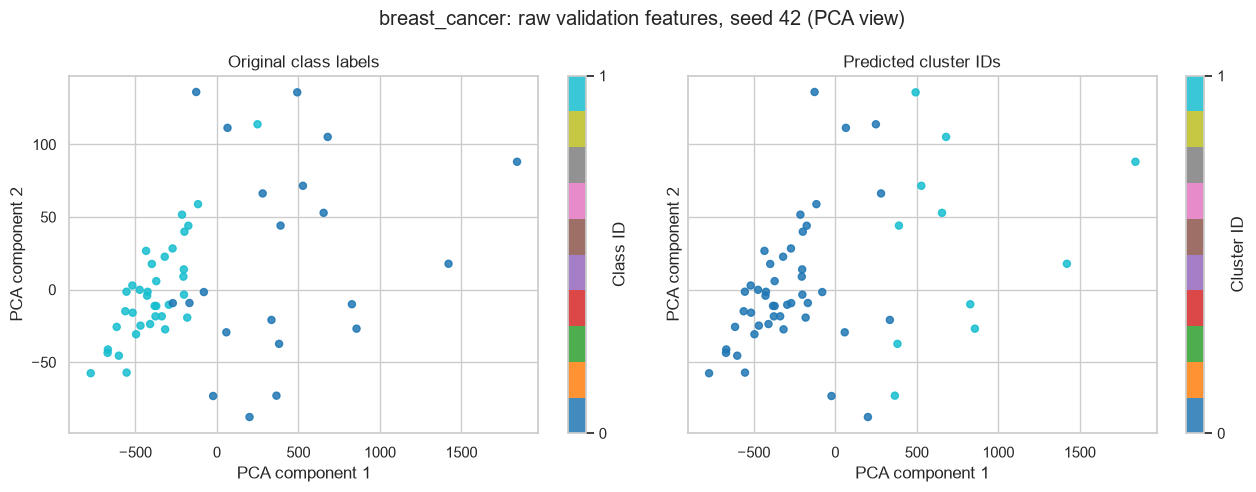

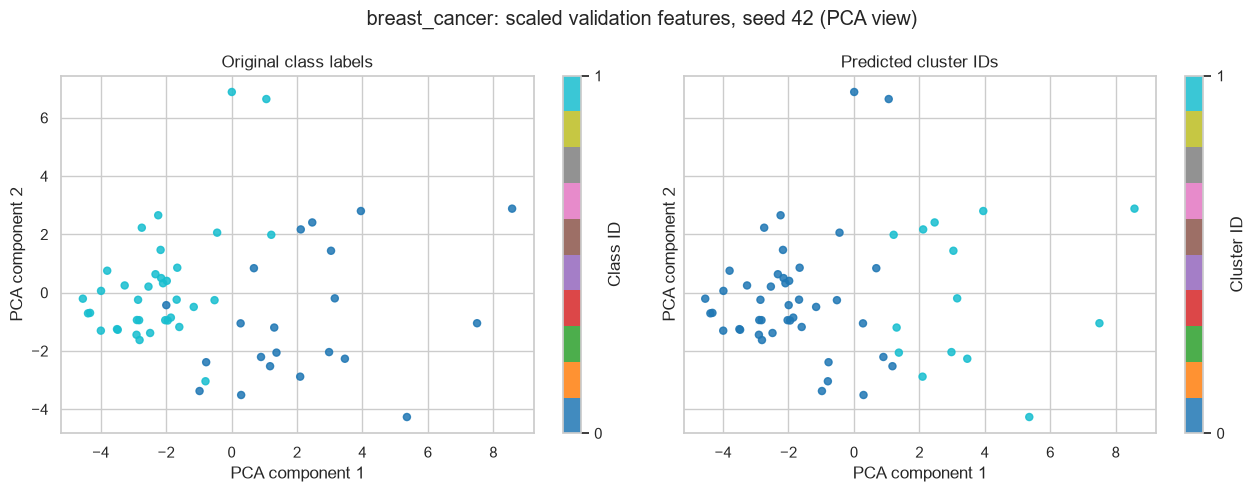

In [44]:

# Visual evidence uses seed 42 only; all three seeds are already in the run table.
seed=42;s=splits[seed]
for rep in ['raw','scaled']:
    tr=s[f'{rep}_train']; va=s[f'{rep}_val']
    km=KMeans(n_clusters=len(CLASS_IDS),random_state=seed,n_init=10).fit(tr)
    clusters=km.predict(va)
    pca=PCA(n_components=2).fit(tr)
    coords=pca.transform(va)
    fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True)
    for ax,colors,ttl in [(axes[0],s['y_val'].to_numpy(),'Original class labels'),(axes[1],clusters,'Predicted cluster IDs')]:
        scatter=ax.scatter(coords[:,0],coords[:,1],c=colors,cmap='tab10',s=26,alpha=.85)
        ax.set(title=ttl,xlabel='PCA component 1',ylabel='PCA component 2')
        fig.colorbar(scatter,ax=ax,label='Class ID' if ax==axes[0] else 'Cluster ID',ticks=range(len(CLASS_IDS)))
    fig.suptitle(f'{DATASET}: {rep} validation features, seed 42 (PCA view)')
    savefig(f'kmeans_{rep}_two_panel')


In [45]:

print('Classification fits:',len(runs),'K-Means fits:',len(cluster_runs),'total fits for this dataset:',len(runs)+len(cluster_runs))
print('Classification summary rows:',len(summary),'K-Means summary rows:',len(cluster_summary))
print('Figure files for this dataset:',len(list(OUT.glob(f'{DATASET}_*.png'))))
print('Test row indices (fixed):',X_test.index.tolist())
assert len(runs)+len(cluster_runs)==72


Classification fits: 66 K-Means fits: 6 total fits for this dataset: 72
Classification summary rows: 22 K-Means summary rows: 2
Figure files for this dataset: 11
Test row indices (fixed): [256, 428, 501, 363, 564, 464, 358, 343, 516, 567, 292, 199, 527, 121, 353, 495, 541, 537, 308, 242, 223, 261, 467, 288, 549, 406, 23, 415, 266, 359, 247, 354, 452, 528, 85, 41, 310, 275, 526, 433, 217, 158, 267, 417, 64, 340, 307, 206, 375, 408, 284, 542, 507, 73, 150, 431, 316, 167, 168, 445, 399, 553, 295, 235, 77, 385, 291, 20, 518, 496, 231, 361, 140, 468, 328, 237, 194, 439, 269, 434, 204, 104, 70, 540, 205, 51, 483, 568, 200, 523, 423, 519, 535, 321, 83, 296, 1, 344, 203, 298, 127, 24, 14, 102, 180, 461, 246, 198, 504, 95, 128, 257, 228, 488]
